# 02 – Preprocessing and baseline models

## Load and clean

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)

df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(0)

df = df.drop(columns=["customerID"])

df["Churn"] = (df["Churn"] == "Yes").astype(int)

print(df.shape, "| missing values:", df.isnull().sum().sum())

(7043, 20) | missing values: 0


## Train/test split

In [16]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate train:", y_train.mean().round(3), "| test:", y_test.mean().round(3))

Train: (5634, 19) | Test: (1409, 19)
Churn rate train: 0.265 | test: 0.265


## Preprocessing pipeline

In [17]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]  # includes SeniorCitizen (already 0/1) and all text columns

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_cols),
])

## Evaluation helper

In [18]:
results = []

def evaluate(name, model):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    }
    results.append(row)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Stayed", "Churned"])
    plt.title(name)
    plt.show()
    return row

## Baseline models

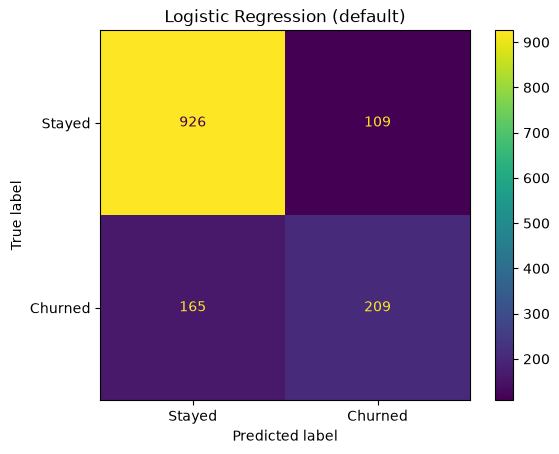

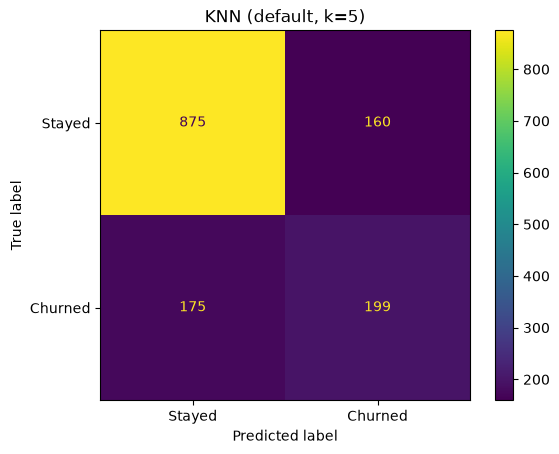

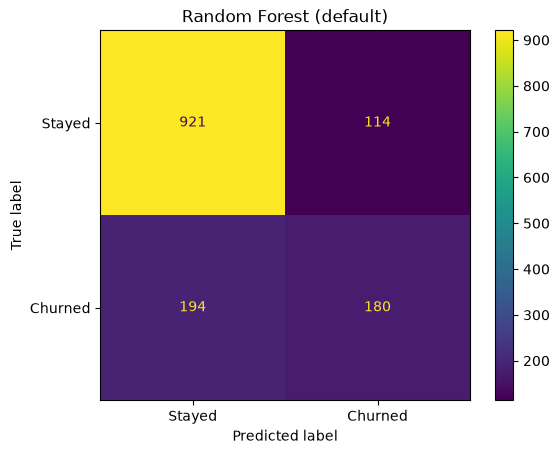

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression (default),0.806,0.657,0.559,0.604,0.842
1,"KNN (default, k=5)",0.762,0.554,0.532,0.543,0.777
2,Random Forest (default),0.781,0.612,0.481,0.539,0.821


In [19]:
models = {
    "Logistic Regression (default)": LogisticRegression(max_iter=1000),
    "KNN (default, k=5)": KNeighborsClassifier(),
    "Random Forest (default)": RandomForestClassifier(random_state=42),
}

for name, clf in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", clf)])
    pipe.fit(X_train, y_train)
    evaluate(name, pipe)

pd.DataFrame(results).round(3)

## Baseline results (default hyperparameters)

- Logistic Regression performed best overall (accuracy 0.806, F1 0.604, ROC-AUC 0.842).
- KNN (k=5) had the weakest ranking ability (ROC-AUC 0.777).
- Random Forest reached ROC-AUC 0.821 but had the lowest recall (0.481), meaning it missed more than half of the churners.
- All three models have recall between 0.48 and 0.56 because the target is imbalanced (26.5% churn). Accuracy alone overstates performance, since predicting "stayed" for everyone would score about 73.5%.
- Next step: hyperparameter tuning and class weighting to improve recall and F1.

## Hyperparameter tuning

In [20]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import RocCurveDisplay

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
tuned = {}

best params: {'model__C': 1, 'model__class_weight': 'balanced'}
best cv f1: 0.629


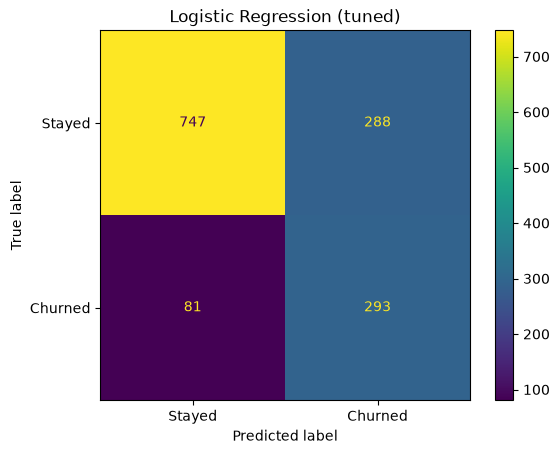

{'Model': 'Logistic Regression (tuned)',
 'Accuracy': 0.7381121362668559,
 'Precision': 0.504302925989673,
 'Recall': 0.7834224598930482,
 'F1': 0.6136125654450262,
 'ROC-AUC': 0.8414890593918727}

In [21]:
lr_pipe = Pipeline([("prep", preprocessor), ("model", LogisticRegression(max_iter=1000))])

lr_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"],
}

lr_search = GridSearchCV(lr_pipe, lr_grid, cv=cv, scoring="f1", n_jobs=-1)
lr_search.fit(X_train, y_train)

print("best params:", lr_search.best_params_)
print("best cv f1:", round(lr_search.best_score_, 3))

tuned["Logistic Regression (tuned)"] = lr_search
evaluate("Logistic Regression (tuned)", lr_search)

best params: {'model__metric': 'manhattan', 'model__n_neighbors': 31, 'model__weights': 'uniform'}
best cv f1: 0.603


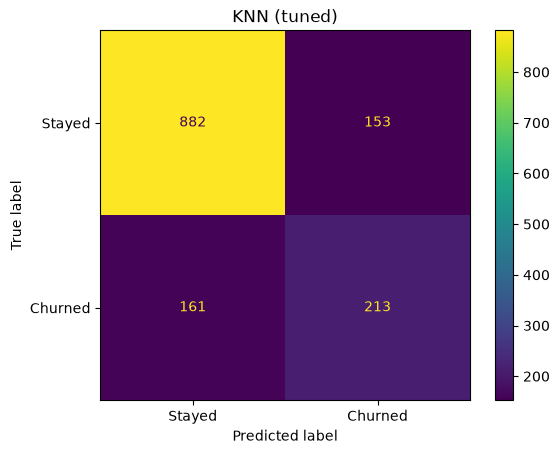

{'Model': 'KNN (tuned)',
 'Accuracy': 0.7771469127040455,
 'Precision': 0.5819672131147541,
 'Recall': 0.56951871657754,
 'F1': 0.5756756756756757,
 'ROC-AUC': 0.8261954584205223}

In [22]:
knn_pipe = Pipeline([("prep", preprocessor), ("model", KNeighborsClassifier())])

knn_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31],
    "model__weights": ["uniform", "distance"],
    "model__metric": ["euclidean", "manhattan"],
}

knn_search = GridSearchCV(knn_pipe, knn_grid, cv=cv, scoring="f1", n_jobs=-1)
knn_search.fit(X_train, y_train)

print("best params:", knn_search.best_params_)
print("best cv f1:", round(knn_search.best_score_, 3))

tuned["KNN (tuned)"] = knn_search
evaluate("KNN (tuned)", knn_search)

best params: {'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__min_samples_leaf': 3, 'model__n_estimators': 300}
best cv f1: 0.636


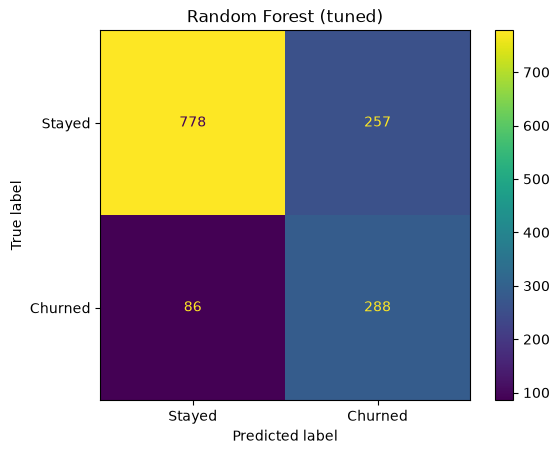

{'Model': 'Random Forest (tuned)',
 'Accuracy': 0.7565649396735273,
 'Precision': 0.5284403669724771,
 'Recall': 0.7700534759358288,
 'F1': 0.6267682263329706,
 'ROC-AUC': 0.8401030768038441}

In [23]:
rf_pipe = Pipeline([("prep", preprocessor), ("model", RandomForestClassifier(random_state=42))])

rf_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 5, 10, 15],
    "model__min_samples_leaf": [1, 3, 5],
    "model__class_weight": [None, "balanced"],
}

rf_search = GridSearchCV(rf_pipe, rf_grid, cv=cv, scoring="f1", n_jobs=-1)
rf_search.fit(X_train, y_train)

print("best params:", rf_search.best_params_)
print("best cv f1:", round(rf_search.best_score_, 3))

tuned["Random Forest (tuned)"] = rf_search
evaluate("Random Forest (tuned)", rf_search)

In [24]:
res = pd.DataFrame(results).round(3)
res["Setting"] = res["Model"].apply(lambda s: "Tuned" if "tuned" in s else "Default")
res = res.sort_values(["Setting", "F1"], ascending=[True, False])
res

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Setting
0,Logistic Regression (default),0.806,0.657,0.559,0.604,0.842,Default
1,"KNN (default, k=5)",0.762,0.554,0.532,0.543,0.777,Default
2,Random Forest (default),0.781,0.612,0.481,0.539,0.821,Default
5,Random Forest (tuned),0.757,0.528,0.770,0.627,0.840,Tuned
3,Logistic Regression (tuned),0.738,0.504,0.783,0.614,0.841,Tuned
4,KNN (tuned),0.777,0.582,0.570,0.576,0.826,Tuned


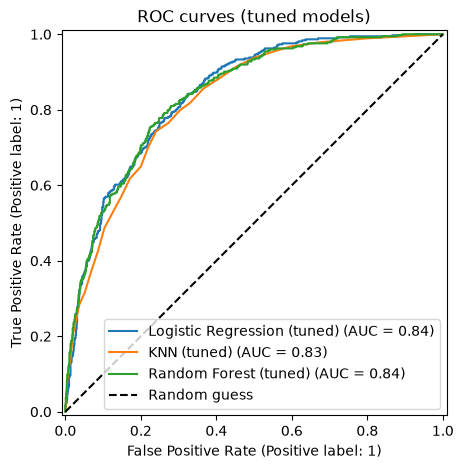

In [25]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, est in tuned.items():
    RocCurveDisplay.from_estimator(est, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_title("ROC curves (tuned models)")
ax.legend(loc="lower right")
plt.show()

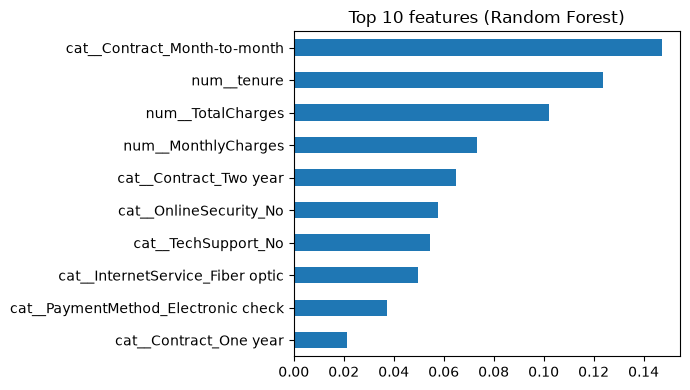

In [26]:
best_rf = rf_search.best_estimator_
names = best_rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(best_rf.named_steps["model"].feature_importances_, index=names)
imp.sort_values(ascending=False).head(10).plot(kind="barh", figsize=(7, 4))
plt.gca().invert_yaxis()
plt.title("Top 10 features (Random Forest)")
plt.tight_layout()
plt.show()

## Tuned results and model comparison

Hyperparameters were tuned with GridSearchCV (5-fold stratified cross-validation on the training set, scoring = F1). The test set was used only for final evaluation.

**Best parameters**
- Logistic Regression: C = 1, class_weight = balanced (CV F1 0.629)
- KNN: k = 31, Manhattan distance, uniform weights (CV F1 0.603)
- Random Forest: 300 trees, max_depth = 10, min_samples_leaf = 3, class_weight = balanced (CV F1 0.636)

**Findings**
- Tuning increased recall substantially for Logistic Regression (0.559 to 0.783) and Random Forest (0.481 to 0.770), mainly through class weighting. This came with lower precision and accuracy, a trade-off that is acceptable when missing a churner is costlier than a false alarm.
- KNN improved in ROC-AUC (0.777 to 0.826) and F1 (0.543 to 0.576) but remained the weakest model, because it has no class-weight option and distances are diluted by many one-hot features.
- Random Forest (tuned) achieved the highest F1 (0.627) and Logistic Regression (tuned) the highest recall (0.783). Their ROC-AUC values are almost identical (0.840 and 0.841).
- Overall, Random Forest (tuned) offers the best balance of recall, F1 and AUC. Logistic Regression (tuned) is a close alternative that is simpler and easier to interpret.

## Fairness check (tuned Random Forest)

In [27]:
pred_rf = rf_search.predict(X_test)

def group_report(col):
    rows = []
    for g in X_test[col].unique():
        m = (X_test[col] == g).values
        rows.append({
            col: g,
            "n": int(m.sum()),
            "actual churn rate": y_test[m].mean(),
            "predicted churn rate": pred_rf[m].mean(),
            "recall": recall_score(y_test[m], pred_rf[m]),
            "precision": precision_score(y_test[m], pred_rf[m]),
        })
    return pd.DataFrame(rows).round(3)

group_report("gender")

,gender,n,actual churn rate,predicted churn rate,recall,precision
0,Male,722,0.251,0.386,0.785,0.509
1,Female,687,0.281,0.387,0.756,0.549


In [28]:
group_report("SeniorCitizen")

,SeniorCitizen,n,actual churn rate,predicted churn rate,recall,precision
0,0,1187,0.233,0.341,0.732,0.499
1,1,222,0.441,0.631,0.878,0.614
